# 第092讲 CPU可复现实验
先读lecture.md与lab.md。本笔记本实际运行相同脚本、测试并显示图像；输出不是手工粘贴。

In [1]:
import sys, pathlib, subprocess, json
print(sys.version)
print('Working directory:', pathlib.Path.cwd())

3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]
Working directory: /workspace/scratch/1577d0a62398/tutorials-20261019/machine-learning/units/092


In [2]:
result=subprocess.run([sys.executable,'experiment.py'],capture_output=True,text=True,check=True)
print(result.stdout)
print('Script exit:',result.returncode)

{
  "device": "cpu",
  "threads": 1,
  "torch": "2.14.1+cpu",
  "python": "3.12.14",
  "data": {
    "kind": "original synthetic bars",
    "train_seed": 920,
    "test_seed": 921,
    "train_n": 384,
    "test_n": 256,
    "image_shape": [
      1,
      12,
      12
    ]
  },
  "budget": "same optimizer updates, batch size, examples, initialization and conv-linear MACs; residual addition is extra",
  "records": [
    {
      "model": "plain",
      "seed": 0,
      "steps": 120,
      "batch": 32,
      "examples_seen": 3840,
      "parameters": 1266,
      "macs_per_example": 176272,
      "approx_conv_linear_flops": 352544,
      "residual_additions": 0,
      "train_seconds": 0.3456595309980912,
      "latency_batch1_ms_median": 0.05663900083163753,
      "latency_batch1_ms_p90": 0.13480439520208168,
      "test_accuracy": 1.0,
      "shifted_accuracy": 1.0,
      "mean_probability_shift": 0.00016674288781359792,
      "last_batch_loss": 0.11639321595430374
    },
    {
      "mo

In [3]:
result=subprocess.run([sys.executable,'-m','unittest','-v','test_experiment.py'],capture_output=True,text=True,check=True)
print(result.stdout+result.stderr)

test_data (test_experiment.TestCNN.test_data) ... ok
test_identity_path (test_experiment.TestCNN.test_identity_path) ... ok
test_shapes_and_gradient (test_experiment.TestCNN.test_shapes_and_gradient) ... ok

----------------------------------------------------------------------
Ran 3 tests in 0.021s

OK



In [4]:
data=json.loads(pathlib.Path('outputs/results.json').read_text())
print('Result fields:', list(data))

Result fields: ['device', 'threads', 'torch', 'python', 'data', 'budget', 'records', 'pooling_original', 'pooling_shifted', 'limitations']


01_synthetic_shapes.png
02_training_budget.png
03_features_pooling.png


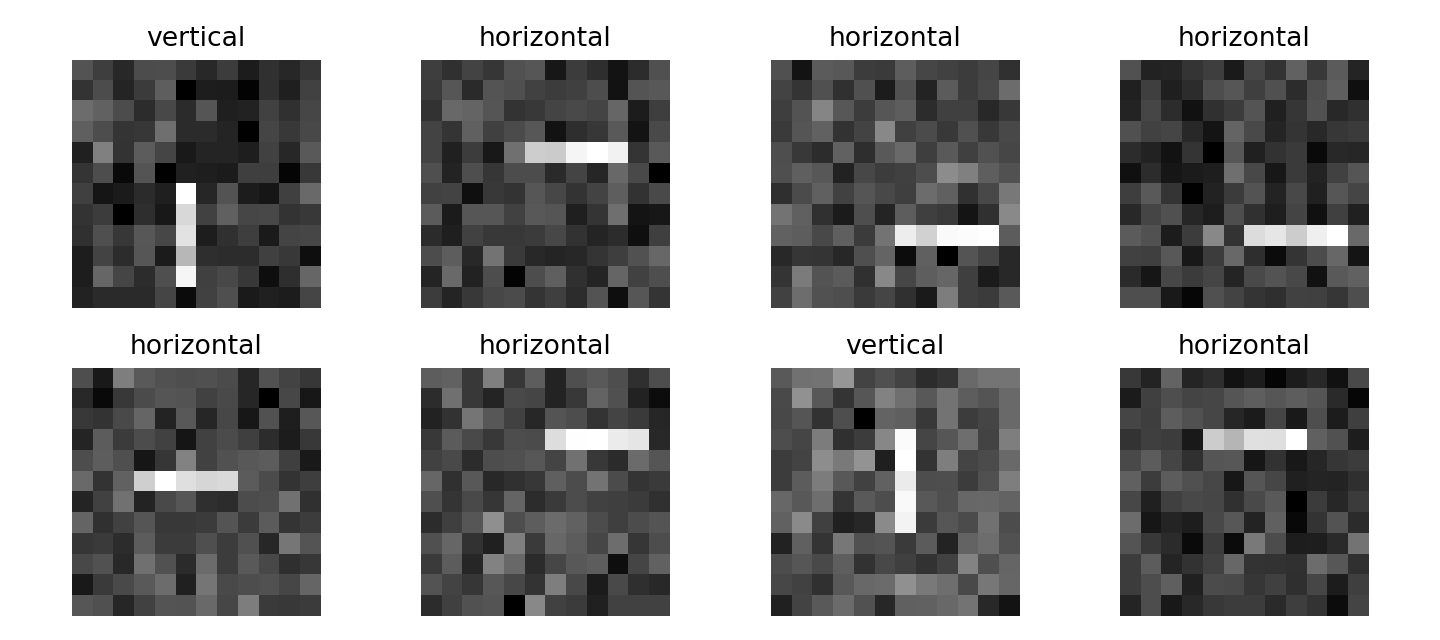

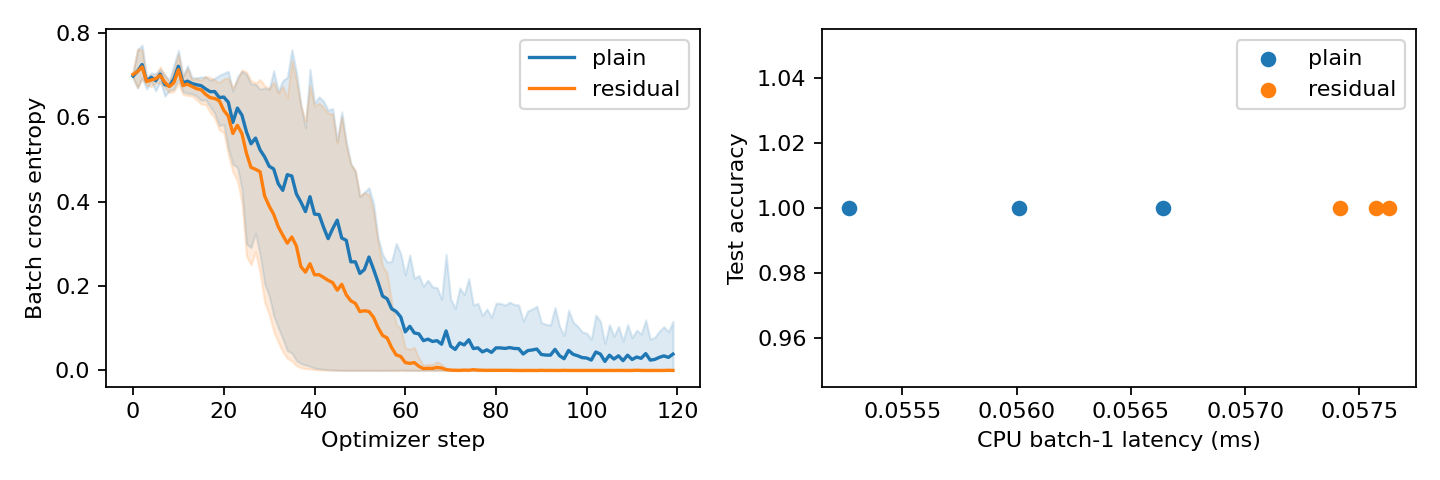

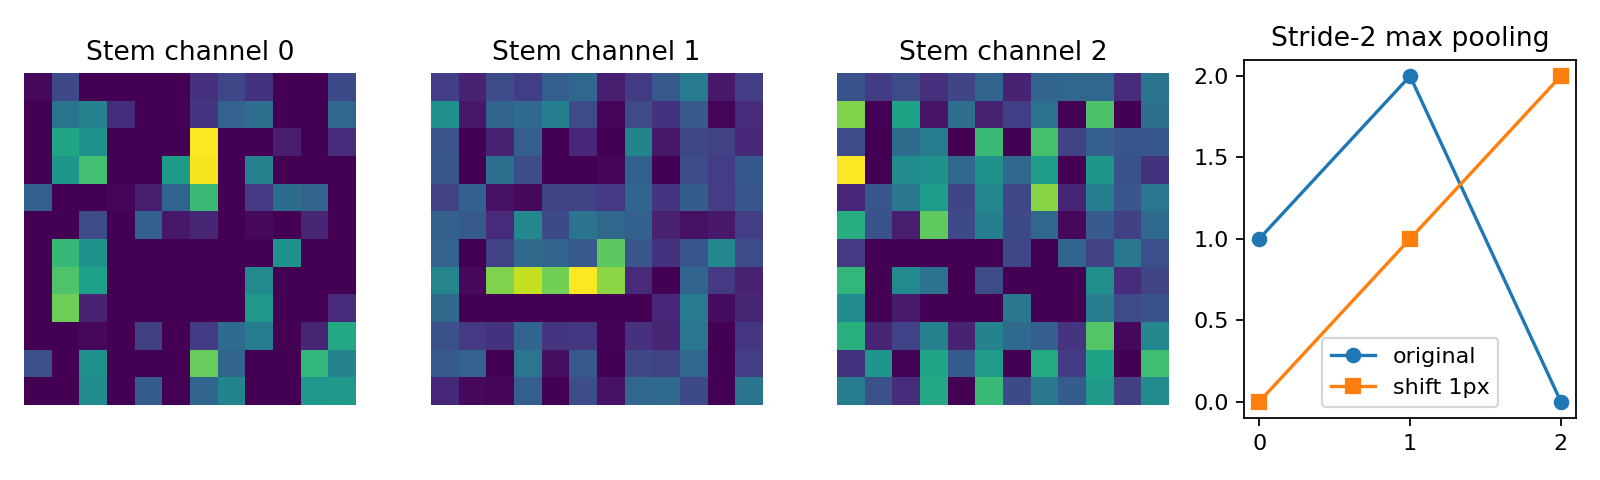

In [5]:
from IPython.display import display, Image
for p in sorted(pathlib.Path('figures').glob('*.png')):
    print(p.name)
    display(Image(filename=str(p)))

解释任务：逐项说明图中的控制变量、预算口径、失败对照和不能支持的结论。详细答案见answers.md。